In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/FDL Project"
DATA_DIR = f"{PROJECT_DIR}/data/flower_photos"
SPLIT_DIR = f"{PROJECT_DIR}/data/splits"
MODEL_DIR = f"{PROJECT_DIR}/models"
SCRIPT_DIR = f"{PROJECT_DIR}/scripts"
PLOT_DIR = f"{PROJECT_DIR}/plots"
HISTORY_DIR = f"{PROJECT_DIR}/history"

In [ ]:
!pip install -q keras-hub

In [ ]:
import sys
import os
import json
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from tensorflow import keras
from tensorflow.keras import mixed_precision
from tensorflow.keras.callbacks import EarlyStopping
import keras_hub


In [ ]:
import os

# Copy the entire "data" folder (images + splits), not just flower_photos.

LOCAL_PROJECT_DIR = "/content/local_project"
LOCAL_DATA_DIR = f"{LOCAL_PROJECT_DIR}/data"

if not os.path.exists(LOCAL_DATA_DIR):
    print("Copying data locally......")
    os.makedirs(LOCAL_PROJECT_DIR, exist_ok=True)
    !cp -r "{PROJECT_DIR}/data" "{LOCAL_DATA_DIR}"
    print("Copy complete")
else:
    print("Data already present locally; skipping the copy.")




Copia dei dati in locale in corso...
Copia completata!


In [ ]:
!du -sh "{PROJECT_DIR}/data"

665M	/content/drive/MyDrive/FDL Project/data


In [ ]:
import os
print(os.path.exists(f"{LOCAL_PROJECT_DIR}/data/splits/train_folds.csv"))  # True
print(os.path.exists(f"{LOCAL_PROJECT_DIR}/data/flower_photos"))           # True

True
True


In [ ]:
if SCRIPT_DIR not in sys.path:
    sys.path.append(SCRIPT_DIR)

from preprocessing import load_common_datasets

## Mixed Precision

In [ ]:
mixed_precision.set_global_policy('mixed_float16')
print(f"Compute dtype: {mixed_precision.global_policy().compute_dtype}")
print(f"Variable dtype: {mixed_precision.global_policy().variable_dtype}")

Compute dtype: float16
Variable dtype: float32


## Initialize Constants

###Model Version Legend



*   2.0 : Base Model w/ Data Augmentation
*   3.0 : Trained with new Resizing Image Logic
*   4.0  :Changes in the dataset
*   5.0 : "train_folds_v2_distributed.csv"
*   6.0 : Trained with new Resizing Image Logic "bilinearity"
* 7.0 : train_file_name="train_folds_v3.csv"





In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CURRENT_DATE = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# TO DO : Change MODEL_NAME, MODEL_VERSION
MODEL_NAME = "ViT_Classifier"
MODEL_VERSION = "v7.0"
MODEL_FILE_NAME= f"{MODEL_NAME}_{MODEL_VERSION}"

In [ ]:
# Create a directory to save your models if it doesn't exist
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)

## Define Data Augmentation

In [ ]:
# TO DO : If needed, change this but must be changed in all notebooks
DATA_AUGMENTATION = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.1),
    keras.layers.RandomBrightness(0.2)
], name="data_augmentation_pipeline")

## Define Initialize model Function

In [ ]:
## Define Initialize Model Function

def initialize_model(num_classes=2, head_dropout=0.2):


    backbone = keras_hub.models.Backbone.from_preset(
        "vit_base_patch16_224_imagenet"
    )
    preprocessor = keras_hub.models.ViTImageClassifierPreprocessor.from_preset(
        "vit_base_patch16_224_imagenet"
    )

    model = keras_hub.models.ViTImageClassifier(
        backbone=backbone,
        preprocessor=preprocessor,
        num_classes=num_classes,
        dropout=head_dropout,   # Dropout(0.2)
        activation=None,        # None = logits;We handle the softmax within the loss function.
        head_dtype="float32",
    )

    # Freeze  backbone
    model.backbone.trainable = False

    print(f"Backbone trainable: {model.backbone.trainable}")
    print(f"Backbone trainable weights: {len(model.backbone.trainable_weights)}")

    trainable = sum(keras.backend.count_params(w) for w in model.trainable_weights)
    non_trainable = sum(keras.backend.count_params(w) for w in model.non_trainable_weights)
    print(f"Trainable params: {trainable:,}")
    print(f"Non-trainable params: {non_trainable:,}")

    model.summary()

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'],
    )

    return model



## Get Number of Folds

In [ ]:
df_main = pd.read_csv(f"{SPLIT_DIR}/train_folds.csv", dtype={'image_path': str, 'fold': int})
unique_folds = sorted(df_main['fold'].unique())
print(f"Found folds: {unique_folds}. \nStarting {len(unique_folds)}-Fold Cross Validation")

Found folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]. 
Starting 5-Fold Cross Validation


## Define Save Model Function

In [ ]:
def save_model(model, current_fold):
  model_name = f"{MODEL_FILE_NAME}_fold_{current_fold}_{CURRENT_DATE}.keras"
  save_path = os.path.join(MODEL_DIR, model_name)

  model.save(save_path)
  print(f"Saved model to: {save_path}")

## Model Training (with Cross Validaiton)

In [ ]:
#!nvidia-smi -l 1

In [ ]:
import pandas as pd
df = pd.read_csv(f"{SPLIT_DIR}/train_folds.csv")
print(df['label'].value_counts())  # Are the 5 classes balanced?
print(df.head(10))

label
1    718
0    638
3    558
4    513
2    505
Name: count, dtype: int64
                                          image_path  label  fold
0  /content/drive/MyDrive/FDL Project/data/flower...      1     0
1  /content/drive/MyDrive/FDL Project/data/flower...      4     1
2  /content/drive/MyDrive/FDL Project/data/flower...      2     2
3  /content/drive/MyDrive/FDL Project/data/flower...      2     4
4  /content/drive/MyDrive/FDL Project/data/flower...      1     2
5  /content/drive/MyDrive/FDL Project/data/flower...      0     4
6  /content/drive/MyDrive/FDL Project/data/flower...      1     0
7  /content/drive/MyDrive/FDL Project/data/flower...      4     3
8  /content/drive/MyDrive/FDL Project/data/flower...      3     2
9  /content/drive/MyDrive/FDL Project/data/flower...      4     4


In [ ]:
all_fold_histories = []
NUM_FOLDS = len(unique_folds)
EPOCHS = 100

for current_fold in unique_folds:
  print(f"========== TRAINING FOLD {current_fold} / {NUM_FOLDS - 1} ==========")

  # PREPARE TRAIN AND VAL DATA HERE
  train_ds, val_ds, test_ds, class_names = load_common_datasets(
      project_dir=LOCAL_PROJECT_DIR,
      val_fold=current_fold,
      img_size=224,
      batch_size=32,
      normalization=None ,
      train_file_name="train_folds_v3.csv"
  )

  num_classes = len(class_names)
  print(f"Detected {num_classes} classes: {class_names}")

  # AUGMENTATION: applied here, outside the model, ONLY on the training set.
    # The preprocessor inside the model will then handle resizing and normalization
    # for both the training and validation/test sets.
  train_ds = train_ds.prefetch(tf.data.AUTOTUNE)


  # quick diagnostic
  if current_fold == unique_folds[0]:
    from preprocessing import summarize_dataset
    summarize_dataset(train_ds, class_names=class_names, max_batches=1)

  # DEFINE MODEL
  model = initialize_model(num_classes=num_classes, head_dropout=0.2)

  # DEFINE EARLY STOPPING
  early_stopping = EarlyStopping(
      monitor='val_loss',
      patience=5,
      restore_best_weights=True,
      verbose=1
  )

  # START TRAINING
  history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[early_stopping])

  # SAVE HISTORY
  all_fold_histories.append(history.history)

  # SAVE MODEL
  save_model(model, current_fold)

========== TRAINING FOLD 0 / 4 ==========
Detected 5 classes: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']
Dataset summary
------------------------------------------------------------
Number of classes: 5
Class names: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']

Batch 1
images.shape: (32, 224, 224, 3)
images.dtype: <dtype: 'float32'>
labels.shape: (32,)
labels.dtype: <dtype: 'int32'>
image min: 0.000
image max: 255.000
first labels: [4 4 0 0 3 0 3 3 4 1]
------------------------------------------------------------
Backbone trainable: False
Backbone trainable weights: 0
Trainable params: 3,845
Non-trainable params: 85,798,656


Preprocessor: "vi_t_image_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ vi_t_image_converter (ViTImageConverter)                      │                   Image size: (224, 224) │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "vi_t_image_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                  ┃ Output Shape                       ┃             Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ images (InputLayer)                           │ (None, 224, 224, 3)                │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ vi_t_backbone (ViTBackbone)                   │ (None, 197, 768)                   │          85,798,656 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ get_item (GetItem)                            │ (None, 768)                        │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ output_dropout (Dropout)                      │ (None, 768)                        │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ predictions (Dense)                           │ (None, 5)                          │               3,845 │
└───────────────────────────────────────────────┴────────────────────────────────────┴─────────────────────┘

 Total params: 85,802,501 (327.31 MB)

... (31 outputs left out)

 Total params: 85,802,501 (327.31 MB)

 Trainable params: 3,845 (15.02 KB)

 Non-trainable params: 85,798,656 (327.30 MB)

Epoch 1/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 42s 337ms/step - accuracy: 0.3119 - loss: 1.7528 - val_accuracy: 0.5595 - val_loss: 1.1445
Epoch 2/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.6446 - loss: 0.9849 - val_accuracy: 0.7655 - val_loss: 0.6915
Epoch 3/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.7955 - loss: 0.6270 - val_accuracy: 0.8419 - val_loss: 0.4982
Epoch 4/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8487 - loss: 0.4754 - val_accuracy: 0.8668 - val_loss: 0.3950
Epoch 5/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.8767 - loss: 0.3877 - val_accuracy: 0.8828 - val_loss: 0.3324
Epoch 6/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.8931 - loss: 0.3304 - val_accuracy: 0.9041 - val_loss: 0.2908
Epoch 7/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9042 - loss: 0.2863 - val_accuracy: 0.9165 - val_loss: 0.2611
Epoch 8/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9206 - loss: 0.2623 - val_accuracy: 

## Save Results

In [ ]:
def plot_cv_results(all_fold_histories):
    epochs_trained = len(all_fold_histories[0]['loss'])
    epochs_range = range(1, epochs_trained + 1)

    plt.figure(figsize=(14, 5))

    # PLOT 1: ACCURACY
    plt.subplot(1, 2, 1)
    for i, history in enumerate(all_fold_histories):
        plt.plot(history['accuracy'], label=f'Train Fold {i}', linestyle='--')
        plt.plot(history['val_accuracy'], label=f'Val Fold {i}', linewidth=2)
    plt.title('Training and Validation Accuracy across Folds')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)

    # PLOT 2: LOSS
    plt.subplot(1, 2, 2)
    for i, history in enumerate(all_fold_histories):
        plt.plot(history['loss'], label=f'Train Fold {i}', linestyle='--')
        plt.plot(history['val_loss'], label=f'Val Fold {i}', linewidth=2)
    plt.title('Training and Validation Loss across Folds')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{MODEL_FILE_NAME}.png", dpi=300, bbox_inches='tight')
    plt.show()

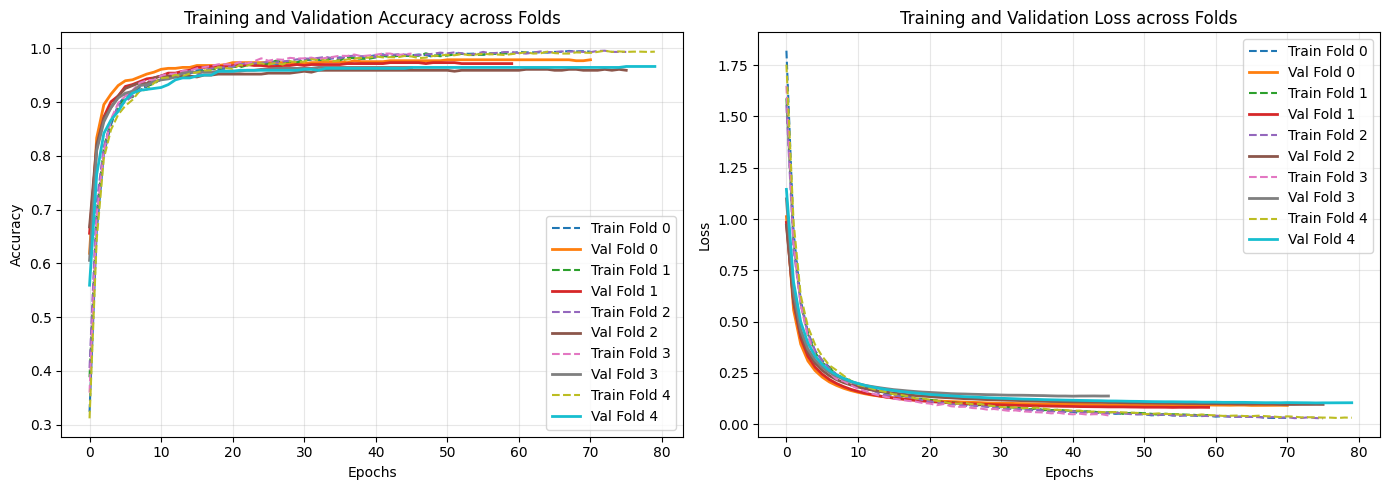

In [ ]:
plot_cv_results(all_fold_histories)

In [ ]:
def save_cv_history(all_fold_histories, filepath):
    def native_convert(obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, (np.float32, np.float64)):
            return float(obj)
        if isinstance(obj, (np.int32, np.int64)):
            return int(obj)
        raise TypeError(f"Object of type {type(obj)} is not JSON serializable")

    with open(filepath, 'w') as f:
        json.dump(all_fold_histories, f, default=native_convert, indent=4)
    print(f"History successfully saved to {filepath}")

In [ ]:
save_cv_history(all_fold_histories, f"{HISTORY_DIR}/{MODEL_FILE_NAME}_history.json")

History successfully saved to /content/drive/MyDrive/FDL Project/history/ViT_Classifier_v7.0_history.json
